# Task 1.2: choose the memory and buffer cutoffs together

A cutoff counts retained Fock states: $N_a$ memory levels and $N_b$ buffer levels. We compare all 36 combinations of $N_a=16,20,24,28,32,40$ and $N_b=4,6,8,10,12,14$, starting from vacuum. The largest pair, $(40,14)$, is the finite numerical reference.

For the separate sweeps, hold $N_b=14$ while varying $N_a$, then hold $N_a=40$ while varying $N_b$. Compare the largest saved memory occupation and the mean over 2.81–3 µs. Relative errors are absolute differences divided by the reference value. The tolerances are 0.5% for the peak and 0.1% for the late-time mean.

To compare the quantum states, use trace distance of the reduced memory density matrices, obtained by tracing out the buffer:

$$
D(t)=\frac12\lVert\rho_a^{(N_a,N_b)}(t)-\rho_a^{(40,14)}(t)\rVert_1.
$$

Add zero rows and columns to put each smaller state in the reference's 40-level basis. The trace norm sums the absolute eigenvalues of the difference. Record $D_{\max}=\max_tD(t)$ over 301 saved times from 0 to 3 µs. This includes populations and coherence. A distance of 0.01 bounds any memory measurement's probability difference from the reference by one percentage point, up to solver error.

The map's black contour marks 1% maximum trace distance. Choosing a cutoff also requires the peak and steady tolerances above and at most 0.1% probability in the highest two memory levels and highest buffer level. These conditions must hold for the candidate and every tested pair with both cutoffs at least as large. The passing pair with the smallest $N_aN_b$ is $(28,12)$; we use $(32,12)$ for additional margin.

The notebook loads saved results by default. Set `RERUN=True` to recompute. Raw reduced-state trajectories are cached locally; the delivered JSON and NPZ contain the comparisons and observable curves.


In [1]:
import sys, json, io
from pathlib import Path
from contextlib import redirect_stdout
from IPython.display import Image, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'src/config.py').is_file() and (p / 'docs/challenge_prompt_v4.md').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
show = lambda name, w=1000: display(Image(filename=str(ROOT / 'figures' / f'{name}.png'), width=w))
load = lambda name: json.loads((ROOT / 'results' / f'{name}.json').read_text())


In [2]:
RERUN = False
if RERUN:
    from tasks import task_1_2
    with redirect_stdout(io.StringIO()):
        task_1_2.main()
r = load('task_1_2')

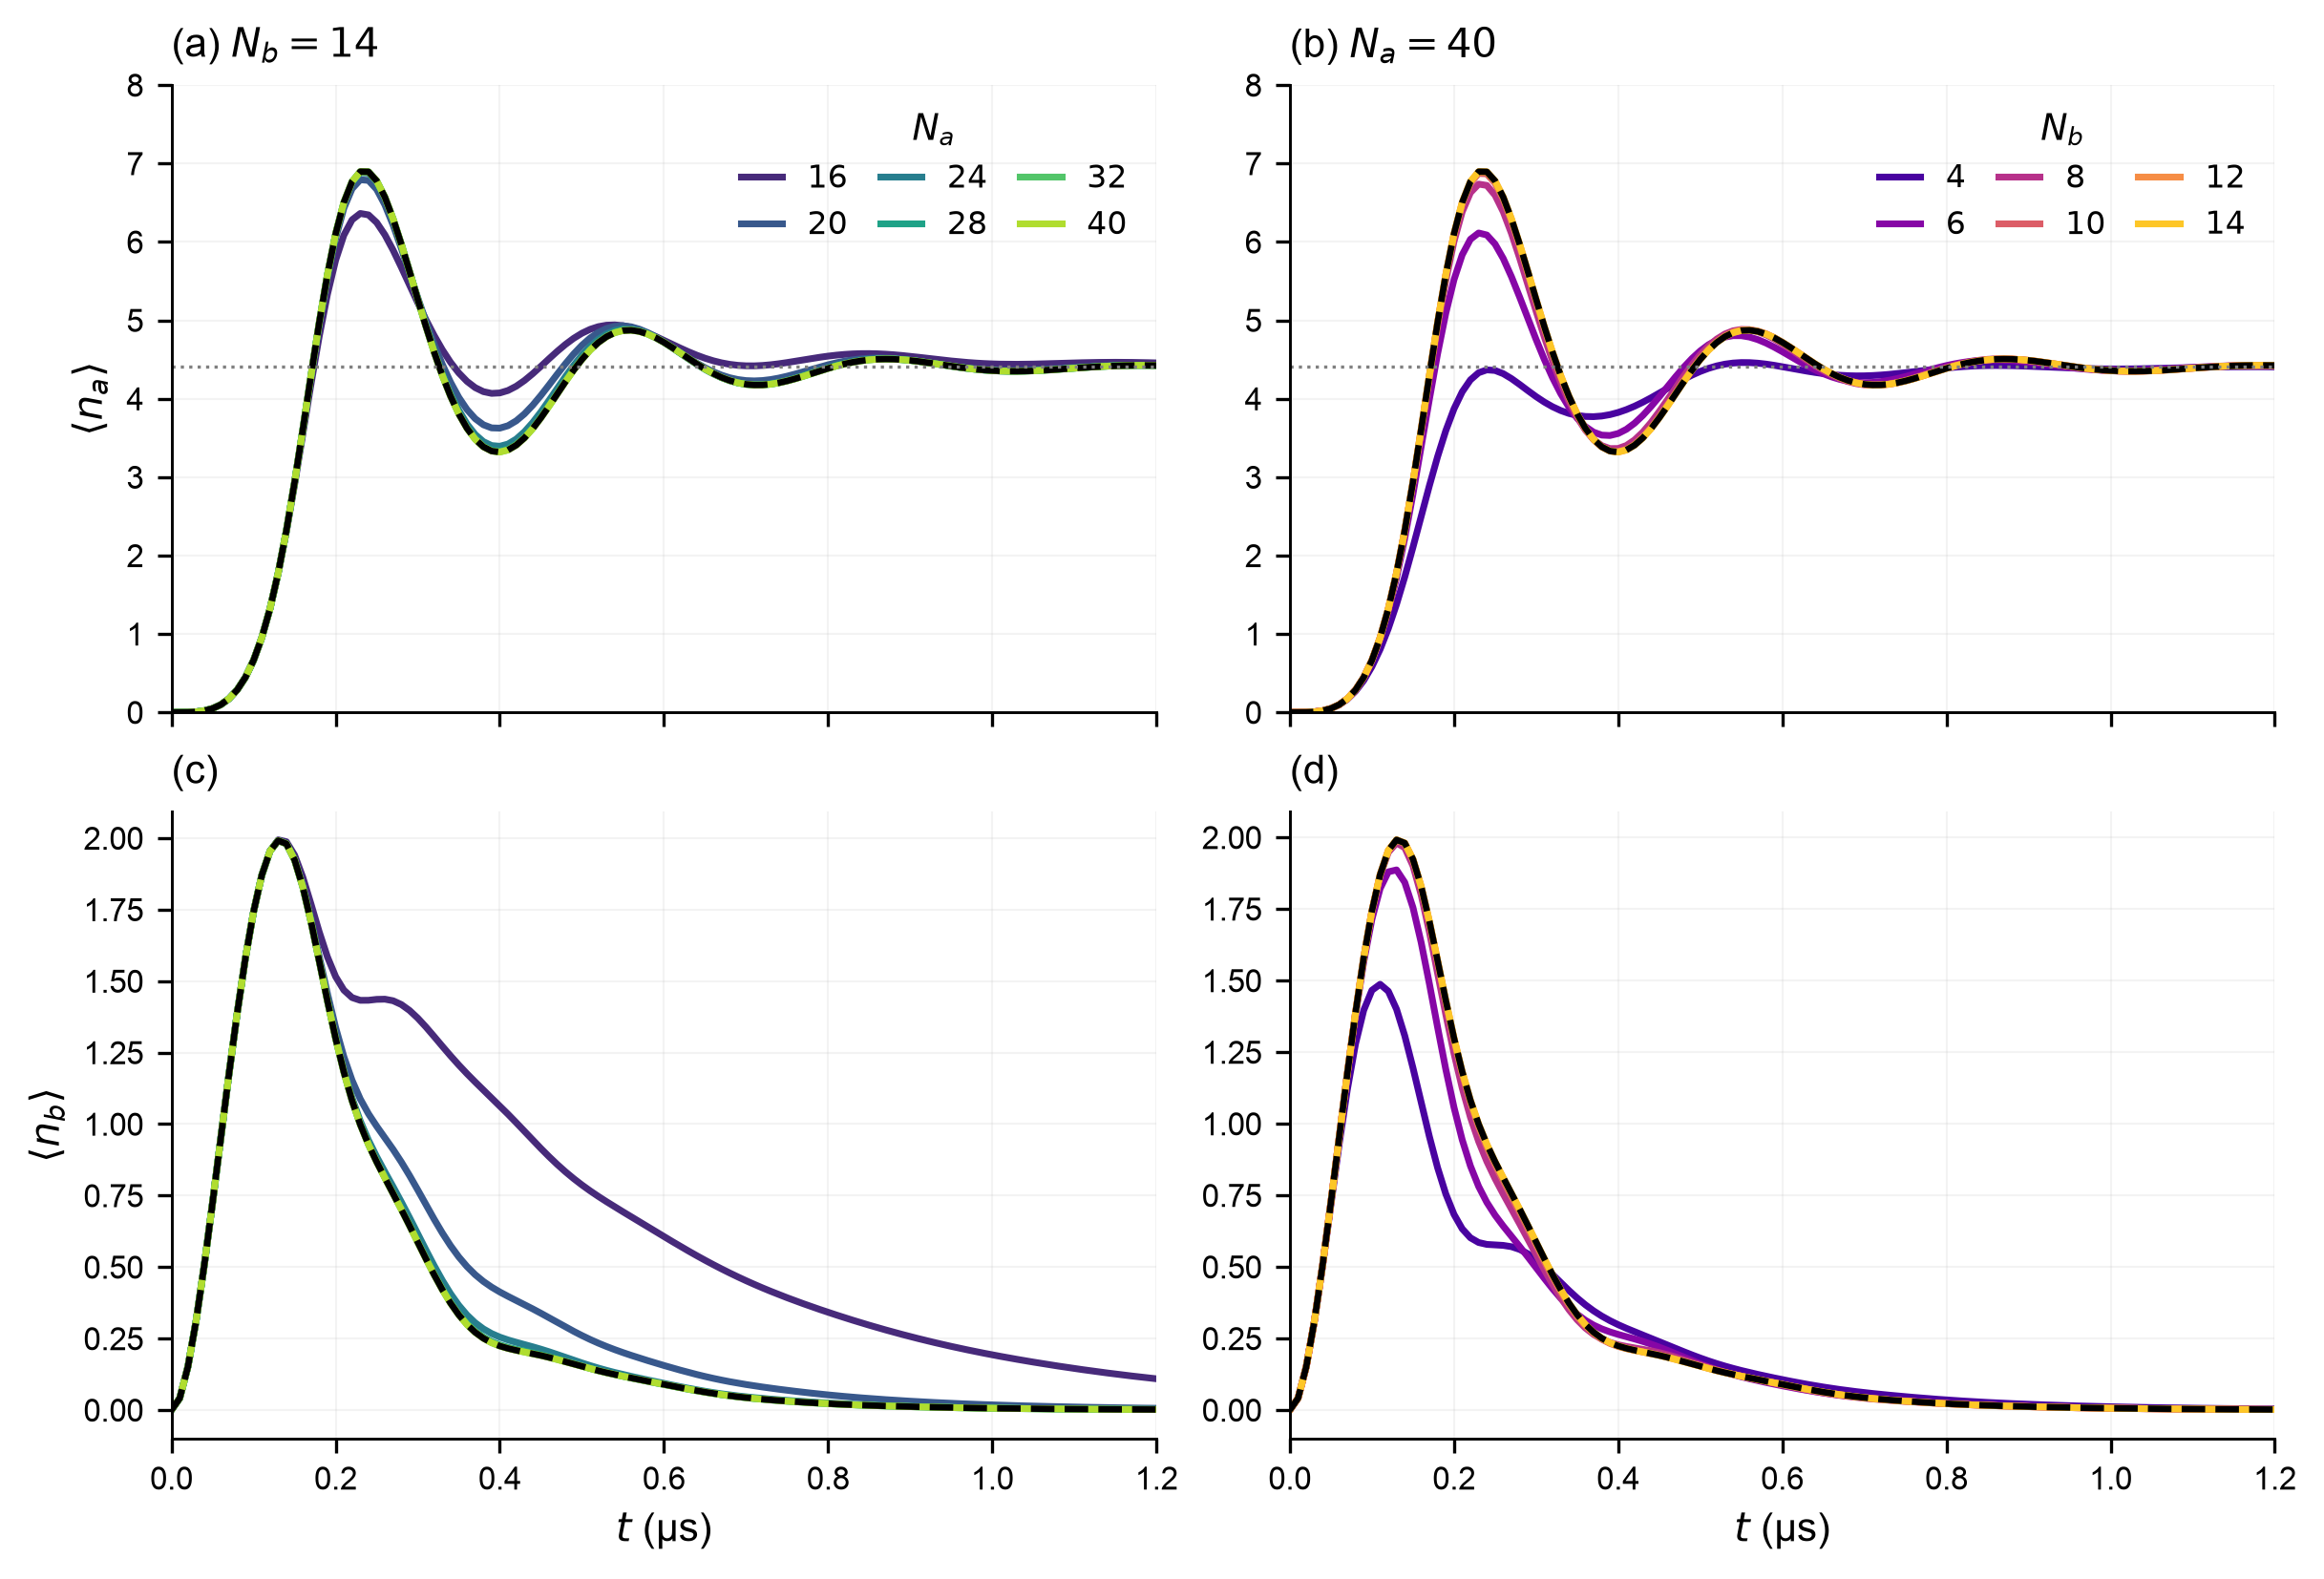

In [3]:
show('task_1_2_cutoff_sweeps', 1050)

**Separate memory and buffer cutoff sweeps.** (a,c) Vary $N_a$ at fixed $N_b=14$; (b,d) vary $N_b$ at fixed $N_a=40$. Color gradients identify the varied cutoff. Upper and lower rows show memory and buffer occupations, respectively. Black dashed curves give the $(40,14)$ reference; horizontal dotted lines mark $\alpha^2$. Only the first $1.2$ µs of each $3$ µs vacuum-inflation trajectory is shown. These are the same grid slices used for the peak and steady-occupation convergence plot.

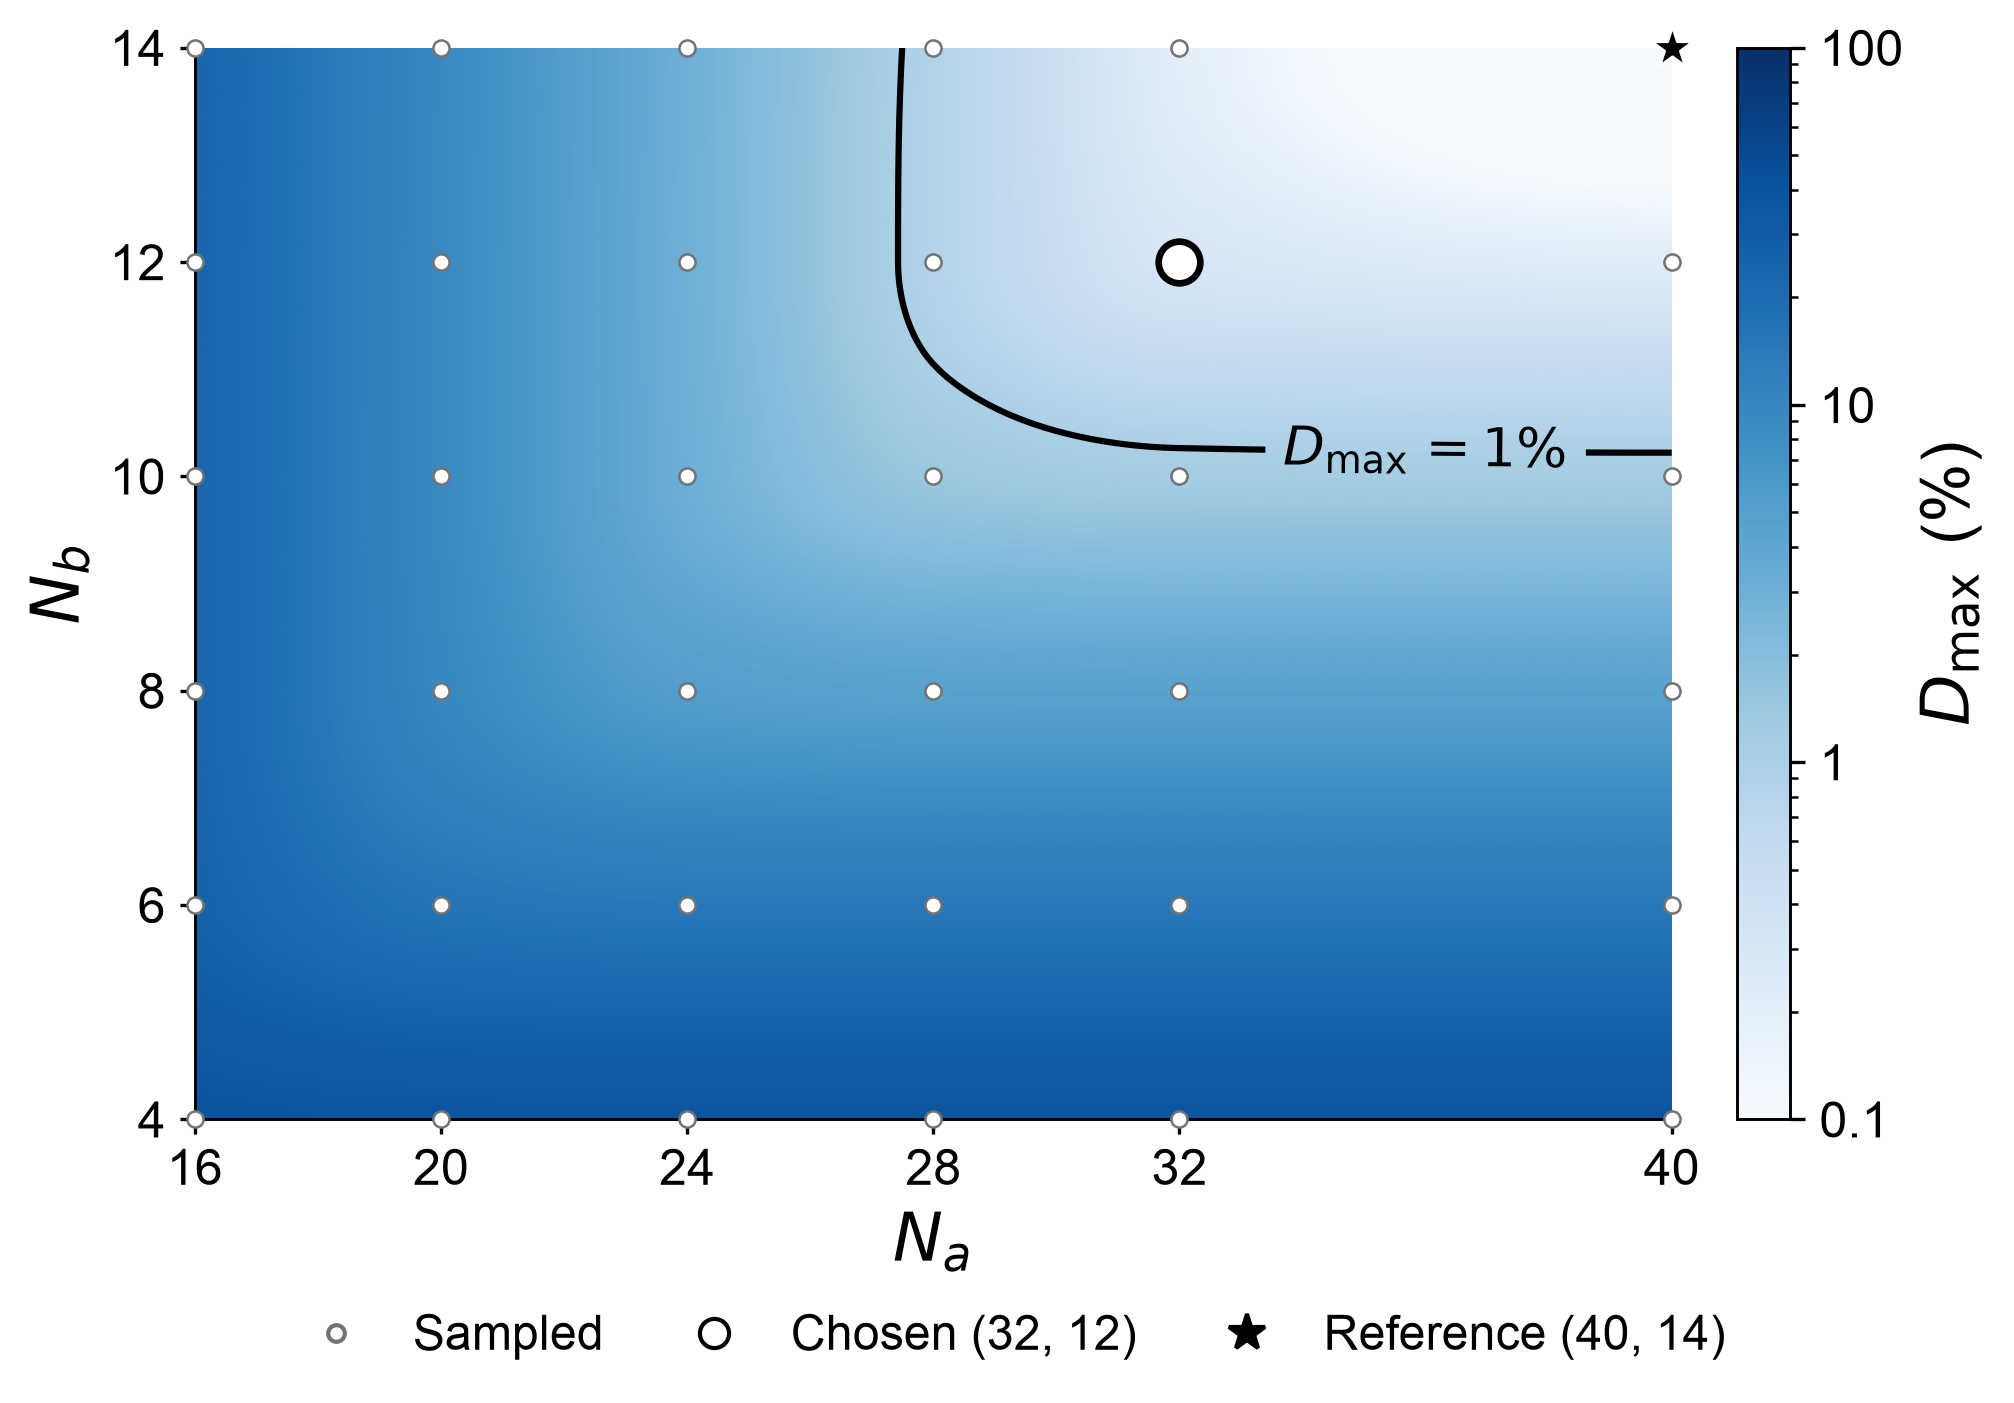

In [4]:
show('task_1_2_error_grid', 1100)

**Joint memory-state convergence.** Axes give the retained memory and buffer dimensions $N_a$ and $N_b$. Blue shading shows maximum trace distance $D_{\max}=\max_t\frac{1}{2}\lVert\rho_a(t)-\rho_{a,\mathrm{ref}}(t)\rVert_1$ relative to $(40,14)$, where $\rho_a$ is the density matrix after tracing out the buffer. Smaller states are zero-padded into the reference basis. Lighter shades mean smaller differences; the color bar is logarithmic in percent, with all values at or below 0.1% sharing the lightest shade. Small circles mark the 36 computed pairs. The black curve marks $D_{\max}=0.01$ (1%); its upper-right side passes this state-distance test. Occupation and top-level-probability criteria are checked separately. The ring marks the chosen cutoff $(32,12)$; the star marks reference $(40,14)$, whose self-distance is zero. Background and contour use the same shape-preserving interpolation; cutoff decisions use computed values. Each maximum covers 301 saved times from 0 to 3 µs.

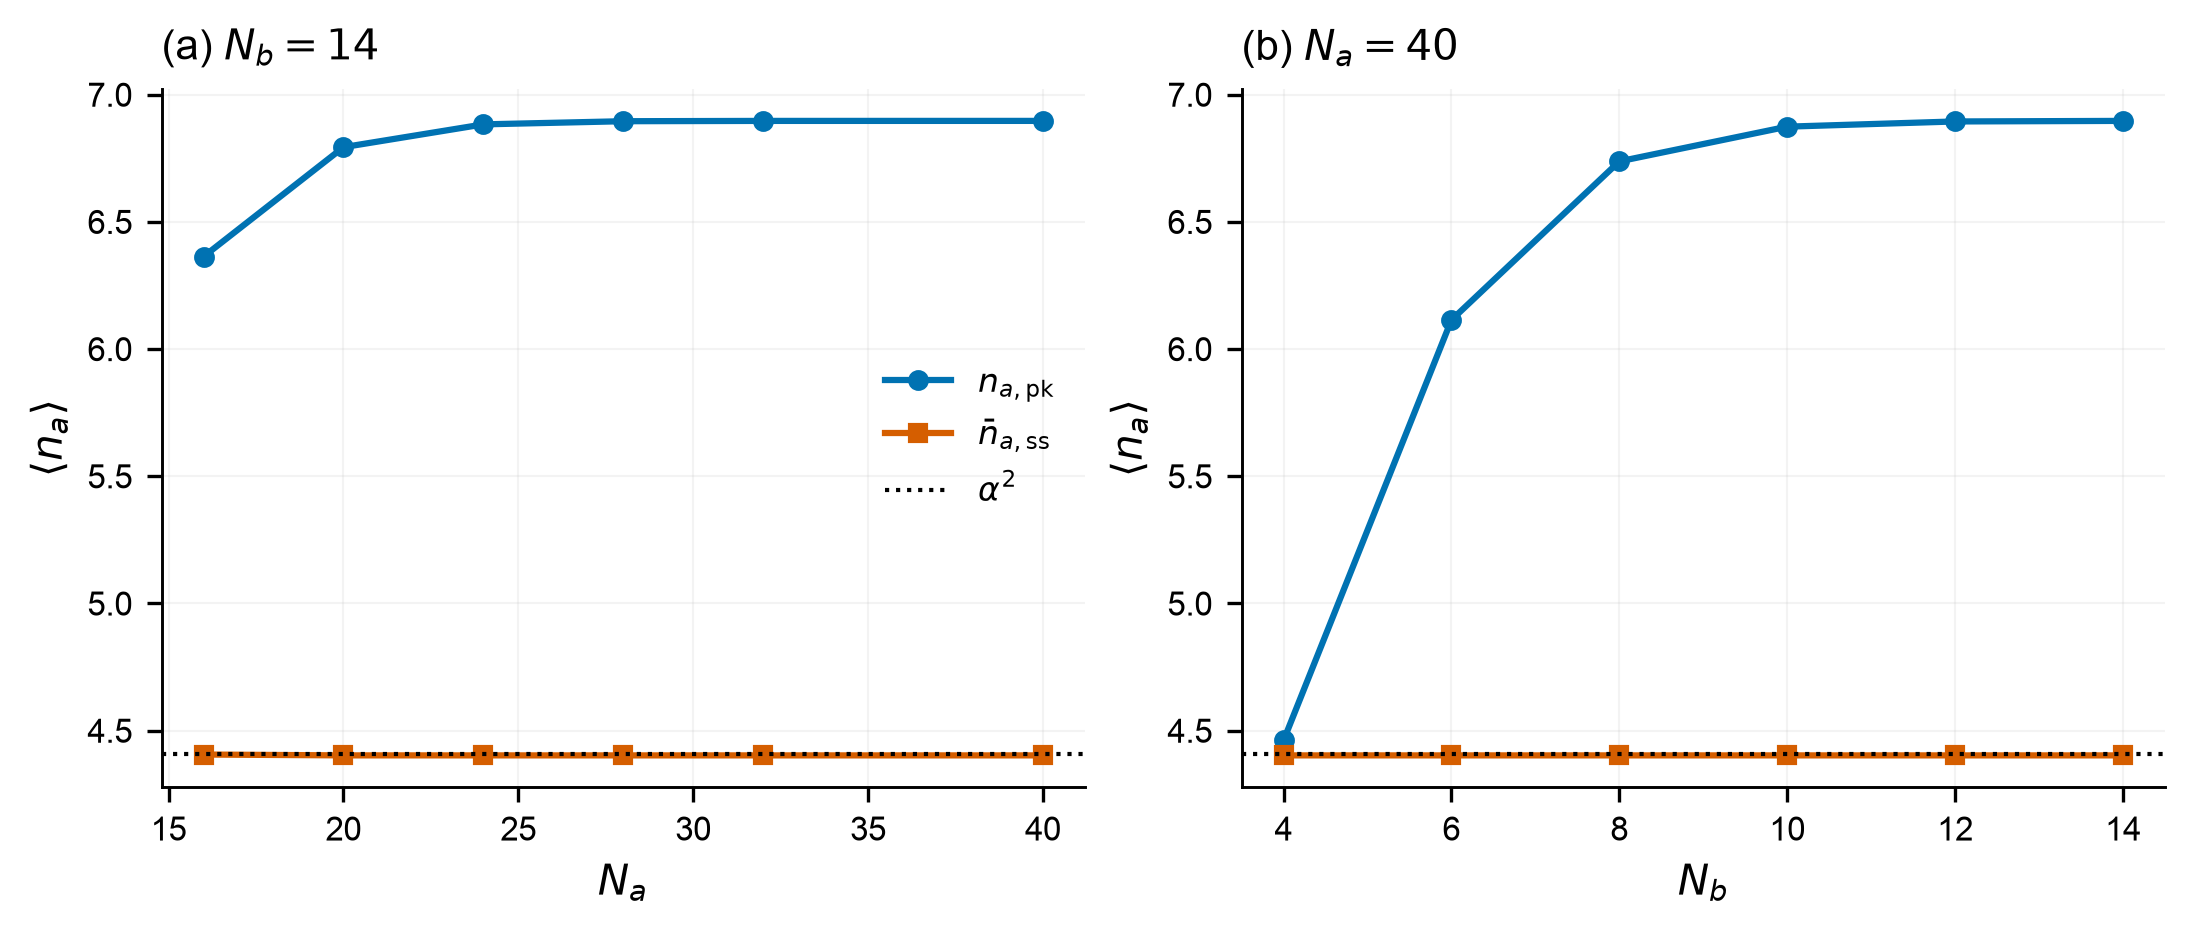

In [5]:
show('task_1_2_convergence', 950)

**Transient and steady occupation versus cutoff.** Peak occupation $n_{a,\mathrm{pk}}=\max_t\langle n_a(t)\rangle$ and late-time mean $\bar n_{a,\mathrm{ss}}$ for (a) varying $N_a$ at $N_b=14$ and (b) varying $N_b$ at $N_a=40$. The steady estimate averages the final 20 saved samples, 2.81–3 µs. Dotted lines mark $\alpha^2$. Both sweeps start from vacuum.

## Numerical summaries

In [6]:
import pandas as pd
grid = pd.DataFrame(r['grid'])
print('Maximum memory-state trace distance (%)')
display((100 * grid.pivot(index='Nb', columns='Na', values='max_trace_distance')).round(4))
comparison = pd.DataFrame([r['summary']['selected'], r['summary']['production']],
                          index=['minimum passing', 'chosen cutoff'])
for key in ['max_trace_distance', 'peak_rel_error', 'steady_rel_error', 'max_top2_a', 'max_top_b']:
    comparison[key + '_pct'] = 100 * comparison[key]
display(comparison[['Na', 'Nb', 'max_trace_distance_pct', 'peak_rel_error_pct',
                    'steady_rel_error_pct', 'max_top2_a_pct', 'max_top_b_pct']].round(6))

Maximum memory-state trace distance (%)


Na,16,20,24,28,32,40
Nb,,,,,,
4,39.7324,37.8039,37.7203,37.7187,37.7187,37.7187
6,25.8002,16.4788,14.8325,14.7281,14.7250,14.7250
8,23.7366,9.7814,5.3205,4.6181,4.5725,4.5710
10,23.8494,9.1003,3.0695,1.4254,1.1749,1.1556
12,24.0914,9.1596,2.9482,0.8481,0.3099,0.2225
14,24.1167,9.2109,2.9960,0.8544,0.2064,0.0000


,Na,Nb,max_trace_distance_pct,peak_rel_error_pct,steady_rel_error_pct,max_top2_a_pct,max_top_b_pct
minimum passing,28,12,0.848127,0.042743,0.000002,0.022173,0.018090
chosen cutoff,32,12,0.309932,0.032475,0.000000,0.001362,0.016921


In [7]:
display(pd.DataFrame(r['sweep_Na']).round(6))
display(pd.DataFrame(r['sweep_Nb']).round(6))

,Na,Nb,wall_s,steady_na,peak_na,t_peak_na,peak_nb,max_top2_a,max_top_b,max_trace_distance,t_max_trace_us,peak_rel_error,steady_rel_error
0,16,14,3.42,4.405958,6.363435,0.23,1.994114,0.057084,0.001223,0.241167,0.23,0.077315,0.000759
1,20,14,5.66,4.402654,6.793373,0.23,1.991775,0.012576,0.000463,0.092109,0.23,0.014975,0.000009
2,24,14,8.87,4.402616,6.882972,0.23,1.991568,0.002025,0.000146,0.029960,0.23,0.001983,0.000000
3,28,14,13.32,4.402616,6.895408,0.23,1.991556,0.000253,0.000040,0.008544,0.24,0.000180,0.000000
4,32,14,21.36,4.402616,6.896581,0.23,1.991555,0.000023,0.000019,0.002064,0.24,0.000010,0.000000
5,40,14,43.01,4.402616,6.896651,0.23,1.991555,0.000000,0.000018,0.000000,0.00,0.000000,0.000000


,Na,Nb,wall_s,steady_na,peak_na,t_peak_na,peak_nb,max_top2_a,max_top_b,max_trace_distance,t_max_trace_us,peak_rel_error,steady_rel_error
0,40,4,1.93,4.402631,4.461620,0.55,1.487084,0.0,0.193312,0.377187,0.21,0.353075,0.000003
1,40,6,4.61,4.402614,6.114285,0.23,1.886514,0.0,0.046242,0.147250,0.23,0.113441,0.000000
2,40,8,10.14,4.402615,6.737568,0.23,1.980652,0.0,0.008641,0.045710,0.26,0.023067,0.000000
3,40,10,17.31,4.402615,6.874000,0.23,1.990813,0.0,0.001323,0.011556,0.27,0.003284,0.000000
4,40,12,29.72,4.402616,6.894430,0.23,1.991520,0.0,0.000169,0.002225,0.27,0.000322,0.000000
5,40,14,43.01,4.402616,6.896651,0.23,1.991555,0.0,0.000018,0.000000,0.00,0.000000,0.000000


The cutoff recommendation applies to inflation from vacuum at the supplied parameters. Recheck it for different cat sizes, initial states or drives. Errors are measured at saved times; the displayed contours and finite reference do not establish an exact continuum error bound.